In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import os, random, time
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchinfo import summary

In [ ]:
data_dir = "/kaggle/input/datasets/rajat95gupta/smartphone-image-denoising-dataset/SIDD_Small_sRGB_Only/Data"
BIN_PATH = "/kaggle/working/sidd_patches.bin"
DONE_PATH = BIN_PATH + ".done"

size = 256        
use_compile = True

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
torch.backends.cudnn.benchmark = True
random.seed(0); np.random.seed(0); torch.manual_seed(0)
print(device)

cuda


In [4]:
scenes = sorted(os.listdir(data_dir))
random.Random(0).shuffle(scenes)

In [5]:
def get_paths(scene):
    path = data_dir + "/" + scene
    files = os.listdir(path)
    nf = next(f for f in files if f.upper().startswith("NOISY"))
    gf = next(f for f in files if f.upper().startswith("GT"))
    return path + "/" + nf, path + "/" + gf

In [ ]:
counts = []
for s in tqdm(scenes):
    with Image.open(get_paths(s)[1]) as im:
        w, h = im.size
    counts.append(((h + (-h) % size) // size) * ((w + (-w) % size) // size))

total = sum(counts)
offsets = np.concatenate([[0], np.cumsum(counts)])
mm_shape = (total, 2, 3, size, size)       # [tiles, (noisy, clean), channels, H, W]
print(f"{total} tiles, {2 * total * 3 * size * size / 1e9:.1f} GB on disk")

  0%|          | 0/160 [00:00<?, ?it/s]

34418 tiles, 13.5 GB on disk


In [ ]:
def load_tiles(path):
    img = np.asarray(Image.open(path).convert("RGB"))                  # (H, W, 3) uint8
    h, w, _ = img.shape
    hp, wp = (-h) % size, (-w) % size
    img = np.pad(img, ((hp // 2, hp - hp // 2), (wp // 2, wp - wp // 2), (0, 0)), mode="reflect")
    H, W, _ = img.shape
    tiles = img.reshape(H // size, size, W // size, size, 3).transpose(0, 2, 4, 1, 3)   # (nH, nW, 3, size, size)
    return tiles.reshape(-1, 3, size, size)

def process(i):
    npath, gpath = get_paths(scenes[i])
    tn, tg = load_tiles(npath), load_tiles(gpath)
    k = counts[i]
    assert len(tn) == k and len(tg) == k
    mm[offsets[i]:offsets[i] + k, 0] = tn      # 0 = noisy
    mm[offsets[i]:offsets[i] + k, 1] = tg      # 1 = clean

In [ ]:
if os.path.exists(DONE_PATH) and os.path.getsize(BIN_PATH) == np.prod(mm_shape):
    print("Found cached tiles, skipping preprocessing")
else:
    mm = np.memmap(BIN_PATH, dtype=np.uint8, mode="w+", shape=mm_shape)
    with ThreadPoolExecutor(4) as ex:
        list(tqdm(ex.map(process, range(len(scenes))), total=len(scenes)))
    mm.flush()
    del mm
    open(DONE_PATH, "w").close()
    print("Finished writing patches to disk!")

  0%|          | 0/160 [00:00<?, ?it/s]

Finished writing patches to disk!


In [ ]:
class SIDD_MemmapDataset(Dataset):
    def __init__(self, bin_path, start_idx, end_idx, total_patches, patch_size):
        self.bin_path = bin_path
        self.start_idx = start_idx
        self.end_idx = end_idx
        self.total_patches = total_patches
        self.patch_size = patch_size
        self._mm = None

    def __len__(self):
        return self.end_idx - self.start_idx

    def _get_memmap(self):
        # lazy init is required for multiprocessing workers
        if self._mm is None:
            self._mm = np.memmap(self.bin_path, dtype=np.uint8, mode="r",
                                 shape=(self.total_patches, 2, 3, self.patch_size, self.patch_size))
        return self._mm

    def __getitem__(self, idx):
        mm = self._get_memmap()
        i = self.start_idx + idx
        pair = np.array(mm[i])
        return torch.from_numpy(pair[0]), torch.from_numpy(pair[1])      # uint8 (3, H, W) each

In [ ]:
def prep(x):
    return x.to(device, non_blocking=True).float().div_(255.0).contiguous(memory_format=torch.channels_last)

def augment(x, y):
    """
    Applies independent random Dihedral Group D4 augmentations (8 symmetries)
    per-sample across a batch on GPU.
    x, y shape: [B, C, H, W]
    """
    B = x.shape[0]
    
    # 1. Random Flips (50% probability per sample)
    h_flip = torch.rand(B, 1, 1, 1, device=x.device) < 0.5
    v_flip = torch.rand(B, 1, 1, 1, device=x.device) < 0.5
    
    x = torch.where(h_flip, x.flip(-1), x)
    y = torch.where(h_flip, y.flip(-1), y)
    
    x = torch.where(v_flip, x.flip(-2), x)
    y = torch.where(v_flip, y.flip(-2), y)
    
    # 2. Random Transpose / Diagonal Flip (50% probability per sample)
    # Combining Flips + Transpose uniformly covers all 8 D4 transformations
    transpose = torch.rand(B, 1, 1, 1, device=x.device) < 0.5
    if transpose.any():
        # Masked transpose swap H and W
        x_trans = x.transpose(-2, -1)
        y_trans = y.transpose(-2, -1)
        
        x = torch.where(transpose, x_trans, x)
        y = torch.where(transpose, y_trans, y)
        
    return x.contiguous(memory_format=torch.channels_last), y.contiguous(memory_format=torch.channels_last)

def PSNR(pred, target, eps=1e-8):
    mse = ((pred.float() - target.float()) ** 2).mean(dim=[1, 2, 3])
    mse = mse.clamp_min(eps)
    return (-10 * torch.log10(mse)).mean()

In [ ]:
class ResBlock(nn.Module):
    """Simple Residual Block with GELU (No BatchNorm)"""
    def __init__(self, channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.GELU(),
            nn.Conv2d(channels, channels, 3, padding=1)
        )

    def forward(self, x):
        return x + self.block(x)


class ModernImageDenoiser(nn.Module):
    def __init__(self, in_channels=3, out_channels=3, c=32):
        super().__init__()

        # --- Initial Feature Extraction ---
        self.head = nn.Conv2d(in_channels, c, 3, padding=1)

        # --- Encoder ---
        self.enc1 = ResBlock(c)
        self.bn1 = nn.BatchNorm2d(c)
        self.down1 = nn.Conv2d(c, 2 * c, 3, stride=2, padding=1)  # Learnable downsampling

        self.enc2 = ResBlock(2 * c)
        self.bn2 = nn.BatchNorm2d(2 * c)
        self.down2 = nn.Conv2d(2 * c, 4 * c, 3, stride=2, padding=1)

        self.enc3 = ResBlock(4 * c)
        self.bn3 = nn.BatchNorm2d(4 * c)
        self.down3 = nn.Conv2d(4 * c, 8 * c, 3, stride=2, padding=1)

        # --- Bottleneck ---
        self.bottleneck = nn.Sequential(
            ResBlock(8 * c),
            ResBlock(8 * c)
        )

        # --- Decoder ---
        self.up3 = nn.ConvTranspose2d(8 * c, 4 * c, kernel_size=2, stride=2)
        self.bn4 = nn.BatchNorm2d(4 * c)
        self.dec3 = nn.Sequential(
            nn.Conv2d(8 * c, 4 * c, 1), # Reduce concatenated channels (8c -> 4c)
            ResBlock(4 * c)
        )

        self.up2 = nn.ConvTranspose2d(4 * c, 2 * c, kernel_size=2, stride=2)
        self.bn5 = nn.BatchNorm2d(2 * c)
        self.dec2 = nn.Sequential(
            nn.Conv2d(4 * c, 2 * c, 1),
            ResBlock(2 * c)
        )

        self.up1 = nn.ConvTranspose2d(2 * c, c, kernel_size=2, stride=2)
        self.bn6 = nn.BatchNorm2d(c)
        self.dec1 = nn.Sequential(
            nn.Conv2d(2 * c, c, 1), 
            ResBlock(c)
        )

        # --- Final Reconstruction ---
        self.tail = nn.Conv2d(c, out_channels, 3, padding=1)

        # Zero-init tail layer for clean global residual start
        nn.init.zeros_(self.tail.weight)
        nn.init.zeros_(self.tail.bias)

    def forward(self, x):
        feat = self.head(x)

        s1 = self.bn1(self.enc1(feat))
        s2 = self.bn2(self.enc2(self.down1(s1)))
        s3 = self.bn3(self.enc3(self.down2(s2)))

        b = self.bottleneck(self.down3(s3))

        d3 = self.dec3(torch.cat([self.bn4(self.up3(b)), s3], dim=1))
        d2 = self.dec2(torch.cat([self.bn5(self.up2(d3)), s2], dim=1))
        d1 = self.dec1(torch.cat([self.bn6(self.up1(d2)), s1], dim=1))

        # Global Residual Learning
        return x + self.tail(d1)

In [35]:
summary(ModernImageDenoiser(c = 16), (1,3,size,size))

Layer (type:depth-idx)                   Output Shape              Param #
ModernImageDenoiser                      [1, 3, 256, 256]          --
├─Conv2d: 1-1                            [1, 16, 256, 256]         448
├─ResBlock: 1-2                          [1, 16, 256, 256]         --
│    └─Sequential: 2-1                   [1, 16, 256, 256]         --
│    │    └─Conv2d: 3-1                  [1, 16, 256, 256]         2,320
│    │    └─GELU: 3-2                    [1, 16, 256, 256]         --
│    │    └─Conv2d: 3-3                  [1, 16, 256, 256]         2,320
├─BatchNorm2d: 1-3                       [1, 16, 256, 256]         32
├─Conv2d: 1-4                            [1, 32, 128, 128]         4,640
├─ResBlock: 1-5                          [1, 32, 128, 128]         --
│    └─Sequential: 2-2                   [1, 32, 128, 128]         --
│    │    └─Conv2d: 3-4                  [1, 32, 128, 128]         9,248
│    │    └─GELU: 3-5                    [1, 32, 128, 128]         --
│ 

In [ ]:
batch_size = 32

# split at a scene boundary (90% of scenes -> train)
n_train_scenes = int(len(scenes) * 0.9)
train_l = sum(counts[:n_train_scenes])
print("train tiles:", train_l, "| val tiles:", total - train_l)

train_ds = SIDD_MemmapDataset(BIN_PATH, 0, train_l, total, size)
val_ds   = SIDD_MemmapDataset(BIN_PATH, train_l, total, total, size)

nw = min(4, os.cpu_count() or 2)
train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                      num_workers=nw, pin_memory=True, persistent_workers=True, prefetch_factor=4)
val_dl   = DataLoader(val_ds, batch_size=batch_size, shuffle=False,
                      num_workers=nw, pin_memory=True, persistent_workers=True, prefetch_factor=4)

train tiles: 31166 | val tiles: 3252


In [ ]:
# BASELINE: PSNR we get by doing nothing (noisy vs clean). The model must beat this.
base_sum, n = 0.0, 0
for xb, yb in val_dl:
    base_sum += PSNR(prep(xb), prep(yb)).item() * xb.size(0)
    n += xb.size(0)
base_psnr = base_sum / n
print(f"Baseline PSNR (noisy vs clean): {base_psnr:.2f} dB")

Baseline PSNR (noisy vs clean): 27.80 dB


In [ ]:
lr = 1e-4
model = ModernImageDenoiser(c=16).to(device).to(memory_format=torch.channels_last)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f}M parameters")
if use_compile:
    model = torch.compile(model)
criterion = nn.L1Loss()

0.94M parameters


In [ ]:
@torch.no_grad()
def evaluate(model, dl):
    model.eval()
    loss_sum = torch.zeros((), device=device)
    psnr_sum = torch.zeros((), device=device)
    n = 0
    for xb, yb in dl:
        x, y = augment(prep(xb), prep(yb))
        with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
            p = model(x)
        p = p.float().clamp(0, 1)                      # clamp before measuring
        bs = x.size(0)
        loss_sum += criterion(p, y) * bs        
        psnr_sum += PSNR(p, y) * bs
        n += bs
    return (loss_sum / n).item(), (psnr_sum / n).item()

In [ ]:
def train(model,train_dl,val_dl,epochs,criterion):

    history = {"train_loss": [], "train_psnr": [], "val_loss": [], "val_psnr": []}
    
    steps = epochs * len(train_dl)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=steps, eta_min=1e-6)
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)
    
    for epoch in range(epochs):
        model.train()
        t0 = time.time()
        
        # running sums live on the GPU -> no .item() sync every step
        loss_sum = torch.zeros((), device=device)
        psnr_sum = torch.zeros((), device=device)
        n = 0
        
        pbar = tqdm(train_dl, desc=f"Epoch {epoch+1}/{epochs} [Train]")
        for step, (xb, yb) in enumerate(pbar):
            inputs, targets = augment(prep(xb), prep(yb))      # uint8 -> [0,1] float on the GPU (no extra /255 here!)
            
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
                outputs = model(inputs)
            loss = criterion(outputs.float(), targets)
            
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)    # guards against loss spikes
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            
            with torch.no_grad():
                bs = inputs.size(0)
                loss_sum += loss.detach() * bs
                psnr_sum += PSNR(outputs.detach().clamp(0, 1), targets) * bs
                n += bs
            
            pbar.set_postfix({
                'loss': f"{loss_sum.item() / n:.6f}",
                'psnr': f"{psnr_sum.item() / n:.3f} dB",
            })
        
        train_loss, train_psnr = loss_sum.item() / n, psnr_sum.item() / n
        val_loss, val_psnr = evaluate(model, val_dl)
        
        for k, v in zip(history, [train_loss, train_psnr, val_loss, val_psnr]):
            history[k].append(v)
        
        print(f"Epoch [{epoch+1}/{epochs}] {time.time() - t0:.0f}s | "
              f"Train Loss: {train_loss:.6f} PSNR: {train_psnr:.3f} dB | "
              f"Val Loss: {val_loss:.6f} PSNR: {val_psnr:.3f} dB")
    return history

In [23]:
hist = train(model,train_dl,val_dl,20,criterion)

Epoch 1/20 [Train]:   0%|          | 0/973 [00:00<?, ?it/s]

W1007 06:34:59.186000 59 torch/_inductor/utils.py:1679] [0/0] Not enough SMs to use max_autotune_gemm mode


Epoch [1/20] 158s | Train Loss: 0.014934 PSNR: 35.351 dB | Val Loss: 0.008922 PSNR: 38.528 dB


Epoch 2/20 [Train]:   0%|          | 0/973 [00:00<?, ?it/s]

Epoch [2/20] 119s | Train Loss: 0.011637 PSNR: 37.127 dB | Val Loss: 0.008313 PSNR: 39.050 dB


...

Epoch [18/20] 119s | Train Loss: 0.008796 PSNR: 39.219 dB | Val Loss: 0.006712 PSNR: 40.718 dB


Epoch 19/20 [Train]:   0%|          | 0/973 [00:00<?, ?it/s]

Epoch [19/20] 119s | Train Loss: 0.008797 PSNR: 39.217 dB | Val Loss: 0.006734 PSNR: 40.692 dB


Epoch 20/20 [Train]:   0%|          | 0/973 [00:00<?, ?it/s]

Epoch [20/20] 119s | Train Loss: 0.008788 PSNR: 39.225 dB | Val Loss: 0.006720 PSNR: 40.709 dB


In [34]:
torch.save(model.state_dict(), 'BlindImgDenoise2.pth')

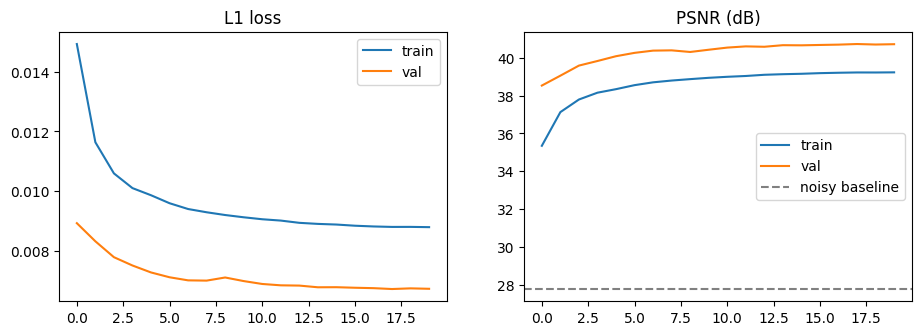

In [25]:
history = hist
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("L1 loss"); ax[0].legend()
ax[1].plot(history["train_psnr"], label="train"); ax[1].plot(history["val_psnr"], label="val")
ax[1].axhline(base_psnr, color="gray", ls="--", label="noisy baseline")
ax[1].set_title("PSNR (dB)"); ax[1].legend()
plt.show()

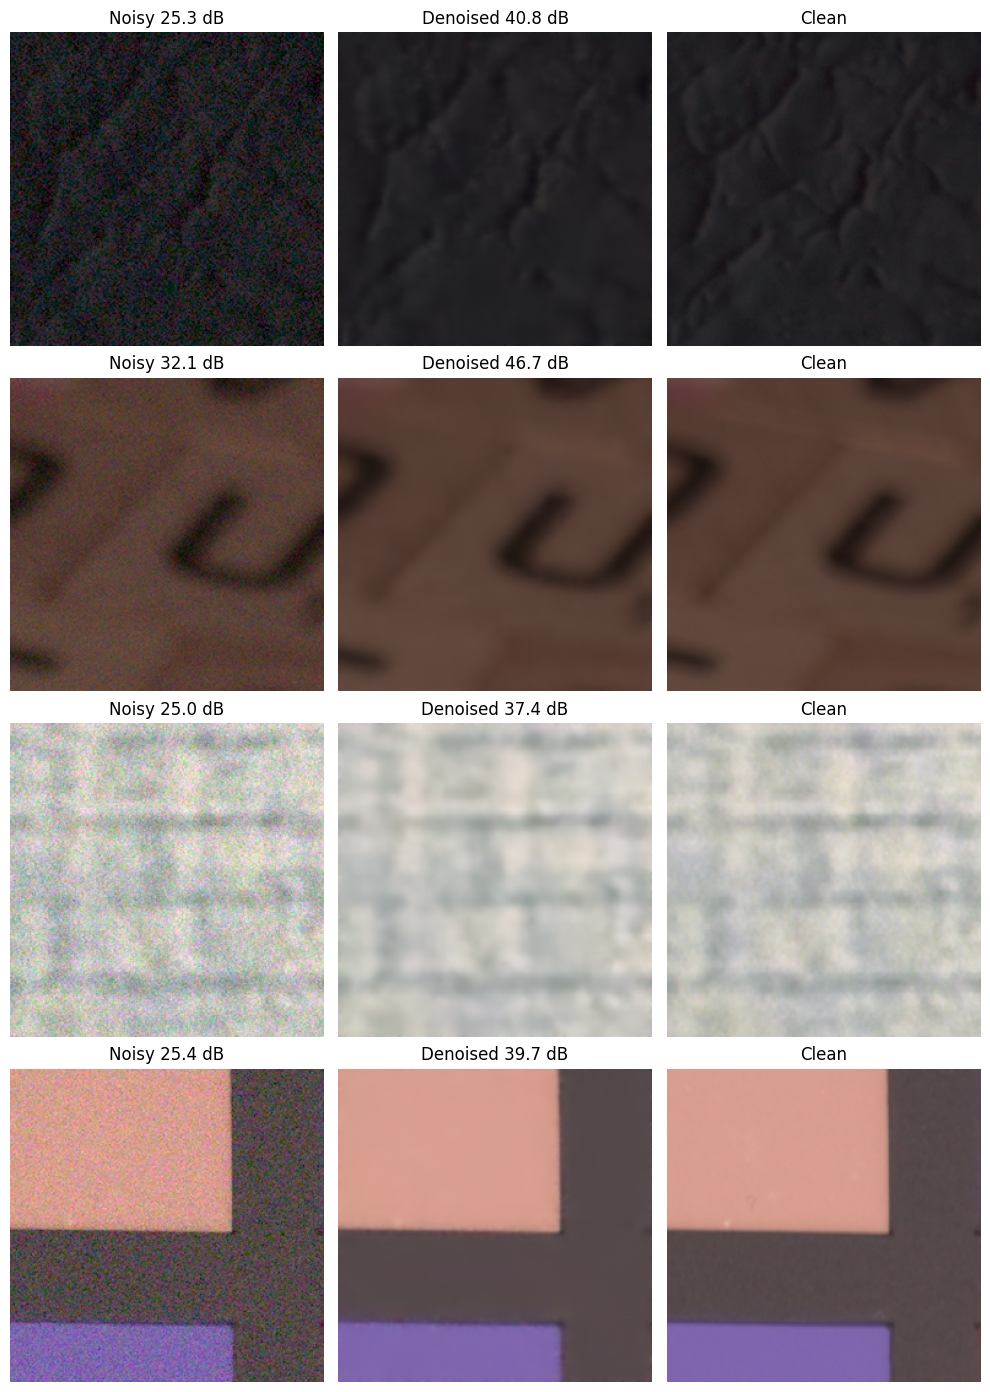

In [54]:
# visual check on a few validation tiles
model.load_state_dict(torch.load("/kaggle/working/BlindImgDenoise2.pth", map_location=device))
model.eval()

idx = random.sample(range(len(val_ds)), 4)
fig, ax = plt.subplots(4, 3, figsize=(10, 14))
for r, i in enumerate(idx):
    xn, yc = val_ds[i]
    x, y = prep(xn[None]), prep(yc[None])
    with torch.no_grad(), torch.autocast(device.type, dtype=torch.float16, enabled=use_amp):
        p = model(x)
    p = p.float().clamp(0, 1)
    for c, (img, title) in enumerate([(x, f"Noisy {PSNR(x, y).item():.1f} dB"),
                                      (p, f"Denoised {PSNR(p, y).item():.1f} dB"),
                                      (y, "Clean")]):
        ax[r, c].imshow(img[0].permute(1, 2, 0).cpu().numpy())
        ax[r, c].set_title(title); ax[r, c].axis("off")
plt.tight_layout(); plt.show()